# Parte 5 · Online Retail: transacciones netas, ajuste y pronóstico

**Autor:** Jorge Armando Ferguson Yaeggy · Grupo 1

**Declaración de uso de IA:** implementación y documentación asistidas por Codex (OpenAI). Se reutilizan la preparación y el pronóstico de Sofía (`resumen_clientes`, `esperado_Y`) y el ajuste manual de Herman (`ajustar_bgnbd`).

Los datos se limpian con la función `limpiar` de nuestra tarea de series de tiempo (copiada en `src/limpieza_retail.py`) y después se arma la venta neta por cliente-día.

Ejecutar desde `notebooks/` mediante **Restart & Run All**. Se verifica el archivo original UCI 352 y se escriben solo los resultados de Retail.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import platform
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import gammaln
from lifetimes import BetaGeoFitter
from IPython.display import display, Markdown

RAIZ=Path.cwd().resolve().parent
assert (RAIZ/'src/datos.py').is_file(), 'Ejecutar desde notebooks/'
sys.path.insert(0,str(RAIZ/'src'))
from limpieza_retail import limpiar, bitacora, netear_por_dia, historias_retail, INICIO_RETAIL, FIN_CALIB_RETAIL, FIN_HOLDOUT_RETAIL
from bgnbd import ajustar_bgnbd, loglik_bgnbd, esperado_Y, p_vivo, NOMBRES
from pronostico_retail import tablas_holdout

RESULTADOS,FIGS=RAIZ/'resultados',RAIZ/'figs'
RESULTADOS.mkdir(exist_ok=True); FIGS.mkdir(exist_ok=True)
def sha(ruta): return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()
def guardar(nombre,valor):
    (RESULTADOS/nombre).write_text(json.dumps(valor,ensure_ascii=False,indent=2,allow_nan=False)+'\n',encoding='utf-8')
versiones={p:metadata.version(p) for p in ['numpy','pandas','scipy','lifetimes','matplotlib','openpyxl','nbclient','nbformat']}
versiones['python']=platform.python_version()
cdnow_antes=sha(RESULTADOS/'params_cdnow.json')
pd.set_option('display.precision',12)
display(pd.Series(versiones,name='Versión').to_frame())

,Versión
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
lifetimes,0.11.3
matplotlib,3.11.2
openpyxl,3.1.5
nbclient,0.11.0
nbformat,5.11.1
python,3.12.3


## Preparación: una transacción es un cliente-día de venta neta positiva

1. **`limpiar` (Tarea 3)** quita las líneas que no son venta: duplicados exactos, facturas con prefijo A (ajustes de deuda), cantidades negativas que no son cancelación, códigos que no son mercancía (envíos, comisiones, muestras) y precios iguales a cero o negativos. Las cancelaciones (facturas C) se conservan porque son devoluciones de ventas reales.
2. Se quedan solo las líneas con `CustomerID`.
3. Por cliente y día se suma `Quantity × UnitPrice`, así que las devoluciones restan. Un día con venta neta **positiva** es una transacción; los días con neto cero o negativo no cuentan.

Las sumas se hacen con `Decimal(str(valor))` convertidos a enteros de escala común, para que el signo de la venta neta no dependa de errores de redondeo.

In [2]:
ruta=RAIZ/'data/Online Retail.xlsx'
SHA_ORIGINAL='43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d'
assert sha(ruta)==SHA_ORIGINAL
origen=json.loads((RAIZ/'data/online_retail_origen.json').read_text())
assert origen['sha256']==SHA_ORIGINAL
raw=pd.read_excel(ruta,engine='openpyxl')
assert len(raw)==541909
assert list(raw.columns)==['InvoiceNo','StockCode','Description','Quantity','InvoiceDate','UnitPrice','CustomerID','Country']
bitacora_limpiar=bitacora(raw)
display(bitacora_limpiar)
limpio=limpiar(raw)
trans,dias,auditoria=netear_por_dia(limpio,devolver_auditoria=True)
auditoria['filas_crudas']=len(raw)
auditoria['bitacora_limpiar']=bitacora_limpiar.to_dict('records')
assert len(dias)==auditoria['dias_cliente_totales']
assert len(trans)+auditoria['dias_neto_cero']+auditoria['dias_neto_negativo']==len(dias)
assert not trans.duplicated(['cliente','fecha']).any()
assert (trans.neto_unidades>0).all()
auditoria['datos_sha256']=SHA_ORIGINAL
auditoria['filas_description_ausente_con_id']=int((raw.Description.isna() & raw.CustomerID.notna()).sum())
auditoria['cantidad_maxima_linea_identificada']=int(raw.loc[raw.CustomerID.notna(),'Quantity'].max())
display(pd.Series({k:v for k,v in auditoria.items() if isinstance(v,(int,str))},name='Auditoría').to_frame())
display(Markdown(f"**Precisión observada:** UnitPrice llega a {auditoria['precision']['decimales_unitprice']} decimales; "
                 f"escala exacta de importes: {auditoria['precision']['escala_importe']}. "
                 f"limpiar conserva {len(limpio):,} de {len(raw):,} líneas; "
                 f"de ellas {auditoria['filas_con_customerid']:,} tienen CustomerID."))
display(pd.Series(auditoria['precision']['distribucion_decimales_unitprice'],name='Líneas por precisión UnitPrice'))
dias.to_csv(RESULTADOS/'retail_dias.csv',index=False)

,regla,filas,monto
0,Duplicados exactos,5268,21740.980000000000
1,Facturas con prefijo A (ajuste de deuda),3,-11062.059999999999
2,Cantidad negativa sin ser cancelación,1336,0.000000000000
3,Códigos que no son mercancía,2259,39792.900999999998
4,Precio igual a cero o negativo,1166,0.000000000000


,Auditoría
limpiar,Tarea 3 (src/limpieza_retail.limpiar) antes de...
filas_originales,531877
filas_sin_customerid,131687
filas_con_customerid,400190
filas_invalidas,0
facturas_unicas_originales,23544
facturas_unicas_con_customerid,22038
filas_sin_factura,0
filas_duplicadas_exactas_originales,0
politica_duplicados,limpiar (Tarea 3) ya quitó los duplicados exactos


**Precisión observada:** UnitPrice llega a 3 decimales; escala exacta de importes: 3. limpiar conserva 531,877 de 541,909 líneas; de ellas 400,190 tienen CustomerID.

1     26948
2    504926
3         3
Name: Líneas por precisión UnitPrice, dtype: int64

## Cohorte y tiempo

Calibración desde el comienzo disponible (01/12/2010) hasta el **30/06/2011 inclusive**;
holdout **01/07–08/12/2011 inclusive**. El 09/12 permanece intacto en el original y
en la auditoría general, pero queda fuera del análisis. Adquisición es el primer
día calificante, no la primera devolución. `resumen_clientes` recibe ya una fila
por cliente-día positivo y semanas desde 01/12/2010. Solo clientes con adquisición
calificante en calibración integran predicciones y observaciones.

In [3]:
res=historias_retail(trans)
calib=trans[trans.fecha<=FIN_CALIB_RETAIL]
hold_todos=trans[(trans.fecha>FIN_CALIB_RETAIL)&(trans.fecha<=FIN_HOLDOUT_RETAIL)]
hold=hold_todos[hold_todos.cliente.isin(res.cliente)]
adquisicion=calib.groupby('cliente').fecha.min()
assert set(res.cliente)==set(calib.cliente)
assert res.cliente.is_unique
assert res.adquisicion.eq(res.cliente.map(adquisicion)).all()
assert res.adquisicion.le(FIN_CALIB_RETAIL).all()
x,tx,T=(res[k].to_numpy(float) for k in ['x','tx','T'])
assert np.isfinite(np.column_stack([x,tx,T,res.x_star])).all()
assert np.all((x>=0)&(x==np.floor(x)))
assert np.all((res.x_star>=0)&(res.x_star==np.floor(res.x_star)))
assert np.all((tx>=0)&(tx<=T)) and np.all(tx[x==0]==0)
assert res['T'].eq((FIN_CALIB_RETAIL-res.adquisicion).dt.days/7).all()
assert res.tx.eq((res.ultima_calibracion-res.adquisicion).dt.days/7).all()
assert int(res.x.sum())==len(calib)-len(res)
assert int(res.x_star.sum())==len(hold)
TAU=(FIN_HOLDOUT_RETAIL-FIN_CALIB_RETAIL).days/7
assert TAU==23 and len(pd.date_range('2011-07-01','2011-12-08'))==161
cohorte={
    'clientes':len(res),'x_cero':int((x==0).sum()),'fraccion_x_cero':float((x==0).mean()),
    'transacciones_calibracion':len(calib),'repetidas_calibracion':int(x.sum()),
    'compras_holdout_cohorte':len(hold),'clientes_sin_compras_holdout':int((res.x_star==0).sum()),
    'clientes_solo_holdout_excluidos':int(hold_todos.loc[~hold_todos.cliente.isin(res.cliente),'cliente'].nunique()),
    'compras_holdout_clientes_nuevos_excluidas':int((~hold_todos.cliente.isin(res.cliente)).sum()),
    'transacciones_9_diciembre_excluidas':int(trans.fecha.eq('2011-12-09').sum()),
    'T_min':float(T.min()),'T_max':float(T.max()),'tx_min':float(tx.min()),'tx_max':float(tx.max()),
    'x_min':int(x.min()),'x_max':int(x.max()),
    'adquisicion_min':res.adquisicion.min().date().isoformat(),'adquisicion_max':res.adquisicion.max().date().isoformat(),
}
auditoria['ventanas_y_cohorte']=cohorte
auditoria['filas_9_diciembre_originales']=int(pd.to_datetime(raw.InvoiceDate).dt.normalize().eq('2011-12-09').sum())
guardar('retail_limpieza_auditoria.json',auditoria)
display(pd.Series(cohorte,name='Cohorte y exclusiones por ventana').to_frame())
display(res[['x','tx','T','x_star']].describe())
distribucion=res.x.value_counts().sort_index().rename_axis('x').reset_index(name='clientes')
distribucion.to_csv(RESULTADOS/'retail_frecuencias.csv',index=False)
display(distribucion)
print('Horizonte exacto:',TAU,'semanas = 161 días')

,Cohorte y exclusiones por ventana
clientes,2958
x_cero,1418
fraccion_x_cero,0.47937795808
transacciones_calibracion,7882
repetidas_calibracion,4924
compras_holdout_cohorte,6319
clientes_sin_compras_holdout,974
clientes_solo_holdout_excluidos,1374
compras_holdout_clientes_nuevos_excluidas,2327
transacciones_9_diciembre_excluidas,34


,x,tx,T,x_star
count,2958.000000000000,2958.000000000000,2958.000000000000,2958.000000000000
mean,1.664638269101,8.520960108181,18.700666473486,2.136240703178
std,3.571356815535,10.070297324045,8.988742556125,3.546020694409
min,0.000000000000,0.000000000000,0.000000000000,0.000000000000
25%,0.000000000000,0.000000000000,11.857142857143,0.000000000000
50%,1.000000000000,2.785714285714,19.285714285714,1.000000000000
75%,2.000000000000,16.714285714286,28.142857142857,3.000000000000
max,58.000000000000,30.142857142857,30.142857142857,70.000000000000


,x,clientes
0,0,1418
1,1,645
2,2,321
3,3,180
4,4,98
5,5,88
6,6,50
7,7,33
8,8,17
9,9,34


Horizonte exacto: 23.0 semanas = 161 días


## 5.1 · Ajuste manual y diagnóstico de identificación

Se reutiliza `ajustar_bgnbd`, sin cambiar cotas ni likelihood. Tres arranques en
escala natural (1,10,.1,1), (.5,5,.01,1) y (1,1,1,1), convertidos a logaritmos,
cubren niveles distintos de intensidad y abandono. Cada uno usa ambos métodos.
La aceptación, tolerancia y recuperación de discrepancias son las de Parte 2.
Una convergencia exitosa en una cota no implica un máximo interior identificado.

In [4]:
inicios_naturales=[[1,10,.1,1],[.5,5,.01,1],[1,1,1,1]]
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter('always')
    estimado,diagnostico=ajustar_bgnbd(x,tx,T,inicios=np.log(inicios_naturales),devolver_diagnostico=True)
params={k:estimado[k] for k in NOMBRES}
ll=loglik_bgnbd(np.log([params[k] for k in NOMBRES]),x,tx,T)
assert diagnostico['aceptado'] and abs(ll-estimado['ll'])<1e-8
display(pd.DataFrame(diagnostico['intentos'])[['id','metodo','indice_inicio','success','status','objetivo','nit','nfev','en_cota','utilizable']])
print('Parámetros completos:',json.dumps(params))
print('LL sumada:',repr(ll))
print('Seleccionado:',diagnostico['seleccionado'],'cotas:',diagnostico['en_cota'])
print('Rango LL exitosos:',diagnostico['rango_ll_exitosos'],'acuerdo según umbral:',diagnostico['acuerdo_ll_exitosos'])
print('Advertencias preservadas:',[str(a.message) for a in avisos])
guardar('params_retail.json',params)

,id,metodo,indice_inicio,success,status,objetivo,nit,nfev,en_cota,utilizable
0,0,Nelder-Mead,0,True,0,5.110613689193,395,724,[],True
1,1,L-BFGS-B,0,True,0,5.110613815607,26,160,[a],True
2,2,Nelder-Mead,1,True,0,5.110613688490,307,576,[a],True
3,3,L-BFGS-B,1,True,0,5.110613730256,26,235,[a],True
4,4,Nelder-Mead,2,True,0,5.110613688586,360,682,[],True
5,5,L-BFGS-B,2,True,0,5.110613887331,28,275,[],True


Parámetros completos: {"r": 0.7398385288684765, "alpha": 9.163516938512174, "a": 4.5399929762484854e-05, "b": 21910.047232075864}
LL sumada: -15117.195290553507
Seleccionado: 2 cotas: ['a']
Rango LL exitosos: 0.0005881703108503444 acuerdo según umbral: False
Advertencias preservadas: ["Parámetros en la cota de búsqueda: ['a']"]


In [5]:
sensibilidad=[]
for intento in diagnostico['intentos']:
    if not intento['utilizable']: continue
    candidato=dict(zip(NOMBRES,np.exp(intento['log_params'])))
    pred=esperado_Y(TAU,x,tx,T,candidato)
    assert np.isfinite(pred).all() and np.all(pred>=0)
    sensibilidad.append({'intento':intento['id'],'metodo':intento['metodo'],**candidato,
        'll':loglik_bgnbd(np.array(intento['log_params']),x,tx,T),
        'abandono_medio':candidato['a']/(candidato['a']+candidato['b']),
        'pronostico_23':float(pred.sum()),'en_cota':','.join(intento['en_cota'])})
sensibilidad=pd.DataFrame(sensibilidad)
sensibilidad['perdida_ll']=ll-sensibilidad.ll
sensibilidad.to_csv(RESULTADOS/'retail_sensibilidad.csv',index=False,float_format='%.17g')
display(sensibilidad)
r,alpha,a,b=(params[k] for k in NOMBRES)
interpretacion={'tasa_semanal_activo':r/alpha,'tasa_anual_activo_52':52*r/alpha,
    'abandono_medio_por_compra':a/(a+b),
    'rango_ll_intentos':diagnostico['rango_ll_exitosos'],
    'rango_pronostico_23':[float(sensibilidad.pronostico_23.min()),float(sensibilidad.pronostico_23.max())],
    'rango_a':[float(sensibilidad.a.min()),float(sensibilidad.a.max())],
    'rango_b':[float(sensibilidad.b.min()),float(sensibilidad.b.max())]}
display(pd.Series(interpretacion,name='Interpretación/sensibilidad').to_frame())
display(Markdown(
    f'**Convergencia e identificación:** {diagnostico["n_exitosos"]} intentos exitosos; '
    f'el seleccionado está cerca de las cotas {diagnostico["en_cota"]}. '
    f'El rango de LL es {diagnostico["rango_ll_exitosos"]:.6g}; '
    f'el acuerdo con el umbral estricto es {diagnostico["acuerdo_ll_exitosos"]}. '
    f'Los b varían de {sensibilidad.b.min():.3g} a {sensibilidad.b.max():.3g}, '
    f'pero el total pronosticado solo de {sensibilidad.pronostico_23.min():.4f} '
    f'a {sensibilidad.pronostico_23.max():.4f}. '
    f'La tasa activa es {r/alpha:.6f}/semana; la media de abandono es {a/(a+b):.4g} por compra. '
    'El resultado se aproxima al límite sin abandono, pero no identifica con precisión a y b '
    'ni demuestra muertes observadas o ausencia real de abandono.'
))

,intento,metodo,r,alpha,a,b,ll,abandono_medio,pronostico_23,en_cota,perdida_ll
0,0,Nelder-Mead,0.739831959227,9.163448149397,0.000076862742,20893.708035766773,-15117.195292633114,0.000000003679,5492.883544566187,,0.000002079607
1,1,L-BFGS-B,0.739839241969,9.163487346259,0.000045399930,146.055386006809,-15117.195666565774,0.000000310840,5492.889043200696,a,0.000376012267
2,2,Nelder-Mead,0.739838528868,9.163516938512,0.000045399930,21910.047232075864,-15117.195290553507,0.000000002072,5492.887508771920,a,0.000000000000
3,3,L-BFGS-B,0.739983799781,9.162582282936,0.000045399930,1020.090048433475,-15117.195414096348,0.000000044506,5493.495329601122,a,0.000123542841
4,4,Nelder-Mead,0.739828207847,9.163411095240,0.000049200645,21865.049242144541,-15117.195290836444,0.000000002250,5492.880948444018,,0.000000282937
5,5,L-BFGS-B,0.739834758853,9.163486385953,0.000184977073,395.912032431977,-15117.195878723818,0.000000467217,5492.872689694625,,0.000588170311


,Interpretación/sensibilidad
tasa_semanal_activo,0.080737399607
tasa_anual_activo_52,4.198344779554
abandono_medio_por_compra,0.000000002072
rango_ll_intentos,0.000588170311
rango_pronostico_23,"[5492.872689694625, 5493.495329601122]"
rango_a,"[0.00004539993, 0.000184977073]"
rango_b,"[146.055386006809, 21910.047232075864]"


**Convergencia e identificación:** 6 intentos exitosos; el seleccionado está cerca de las cotas ['a']. El rango de LL es 0.00058817; el acuerdo con el umbral estricto es False. Los b varían de 146 a 2.19e+04, pero el total pronosticado solo de 5492.8727 a 5493.4953. La tasa activa es 0.080737/semana; la media de abandono es 2.072e-09 por compra. El resultado se aproxima al límite sin abandono, pero no identifica con precisión a y b ni demuestra muertes observadas o ausencia real de abandono.

> **Pregunta 5.1.** ¿Qué le pasó al modelo y qué quiere decir eso sobre la muerte de los clientes? ¿Por qué pasa con estos datos y no con CDNOW?

**Qué le pasó.** El optimizador manda $a$ a la cota inferior ($a \approx 4.5\times10^{-5} = e^{-10}$) y $b$ a valores enormes (entre 146 y ≈ 22 000 según el arranque, todos con prácticamente la misma log-verosimilitud). La probabilidad media de morir después de una compra, $a/(a+b)$, queda en ≈ $2\times10^{-9}$: **el modelo decide que nadie se muere** y el BG/NBD se reduce a un NBD (compras Poisson con tasas gamma, sin proceso de muerte). Que $b$ cambie tanto sin que cambie la verosimilitud, ni el total pronosticado (≈ 5 493 en todos los arranques), dice que los datos no traen información sobre la muerte: no es que el modelo "demuestre" que nadie deja de comprar, es que en esta ventana no ve a nadie hacerlo.

**Por qué aquí y no en CDNOW.**

- **Quiénes son los clientes.** Online Retail vende regalos sobre todo a mayoristas y revendedores, que compran de forma regular para surtir su negocio. La tasa de compra de un activo es $r/\alpha \approx 0.081$ por semana (≈ 4.2 al año) contra ≈ 0.055 (≈ 2.9 al año) en CDNOW, y solo el 48 % no repite en calibración contra el 60 % en CDNOW. Los compradores de CDs de 1997 eran consumidores finales, muchos de una sola compra, y ahí sí hay muerte: $a/(a+b) \approx 0.25$.
- **Cuánto dura la calibración.** Aquí la calibración va del 1 de diciembre de 2010 al 30 de junio de 2011: como mucho 30 semanas, y $T$ promedio de solo 18.7. En CDNOW todos tienen entre 27 y 39 semanas. Con menos tiempo es más difícil distinguir a un cliente que murió de uno que simplemente no ha vuelto todavía.
- **La cohorte no es de clientes nuevos.** En CDNOW la primera compra es de verdad la primera (la cohorte se armó con clientes adquiridos en el primer trimestre de 1997). Aquí "primera compra" es solo la primera que aparece en el archivo: muchos clientes ya compraban antes de diciembre de 2010. Son clientes que ya sobrevivieron, y los que se iban a ir pronto se fueron antes de que empezaran los datos. El modelo ve una base madura y estable, no una cohorte recién adquirida.


## 5.2 · Compras futuras condicionales en 23 semanas

Se evalúa `esperado_Y(23,x,tx,T,params)` de Sofía para la misma cohorte que aporta
`x_star`. Se verifican cero, finitud, no negatividad y monotonía por cliente en los
162 extremos diarios. Los incrementos semanales son diferencias de acumulados:
01–07 julio hasta 02–08 diciembre, 23 intervalos de siete días.

In [6]:
pred23=esperado_Y(TAU,x,tx,T,params)
diario,semanal,mensual=tablas_holdout(trans,res,params)
assert np.isfinite(pred23).all() and np.all(pred23>=0)
assert np.allclose(esperado_Y(0,x,tx,T,params),0,atol=1e-12,rtol=0)
total_pred=float(pred23.sum()); total_real=int(res.x_star.sum())
assert np.isclose(diario.pronostico.sum(),total_pred,rtol=1e-12,atol=1e-8)
assert semanal.real.sum()==mensual.real.sum()==total_real
res['esperado_23']=pred23
res.to_csv(RESULTADOS/'retail_clientes.csv',index=False,float_format='%.17g')
diario.to_csv(RESULTADOS/'retail_diario.csv',index=False,float_format='%.17g')
semanal.to_csv(RESULTADOS/'retail_semanal.csv',index=False,float_format='%.17g')
mensual.to_csv(RESULTADOS/'retail_mensual.csv',index=False,float_format='%.17g')
error=total_pred-total_real
holdout={'fin_calibracion':FIN_CALIB_RETAIL.date().isoformat(),'inicio_holdout':'2011-07-01',
    'fin_holdout':FIN_HOLDOUT_RETAIL.date().isoformat(),'dias':161,'tau_semanas':TAU,
    'unidad':'transacciones cliente-día de venta neta > 0', 'cohorte':cohorte,
    'pronostico_total':total_pred,'real_total':total_real,'error_firmado':error,
    'error_absoluto':abs(error),'error_porcentual':100*error/total_real if total_real else None,
    'convencion_error':'pronóstico menos observado; porcentaje = 100*(pronóstico-observado)/observado',
    'prediccion_cliente_min':float(pred23.min()),'prediccion_cliente_max':float(pred23.max()),
    'finitud_no_negatividad_monotonia_diaria_verificadas':True}
display(pd.Series({k:v for k,v in holdout.items() if not isinstance(v,dict)},name='Resultado holdout').to_frame())

,Resultado holdout
fin_calibracion,2011-06-30
inicio_holdout,2011-07-01
fin_holdout,2011-12-08
dias,161
tau_semanas,23.0
unidad,transacciones cliente-día de venta neta > 0
pronostico_total,5492.88750877192
real_total,6319
error_firmado,-826.11249122808
error_absoluto,826.11249122808


### Verificación al mismo vector de parámetros

`lifetimes` se usa sin ajustar: se asigna el mismo vector publicado y se comparan
expectativas en 0, 1, 4, 13 y 23 semanas. No se presenta una estimación independiente
regularizada como si fuera el mismo ajuste.

Comprobación analítica adicional: dado vivo, λ sigue Gamma(k=r+x, tasa c=α+T) y
p sigue Beta(a,b+x), independientes. Para λ,p fijos, el número esperado es
`(1-exp(-λ*p*tau))/p`. De `z-z²/2 <= 1-exp(-z) <= z` se obtienen límites:

`P(vivo) * [k*tau/c - k*(k+1)*E[p]*tau²/(2*c²)] <= E[Y] <= P(vivo)*k*tau/c`.

En este régimen casi sin abandono los límites son estrechos. Se admite error
numérico relativo de 1e-7 (absoluto mínimo 1e-7 por cliente), sin modificar ni
recortar predicciones. El límite NBD y la precisión del algoritmo son referencias,
no un cambio de modelo ni una estimación de abandono exactamente cero.

In [7]:
bgf=BetaGeoFitter(penalizer_coef=0.0)
bgf.params_=pd.Series(params)
comparaciones=[]
for tau in [0,1,4,13,23]:
    propio=esperado_Y(tau,x,tx,T,params)
    ref=np.asarray(bgf.conditional_expected_number_of_purchases_up_to_time(tau,x,tx,T))
    assert np.isfinite(ref).all()
    np.testing.assert_allclose(propio,ref,rtol=1e-7,atol=1e-8)
    comparaciones.append({'tau':tau,'max_diferencia_absoluta':float(np.abs(propio-ref).max())})
k,c=r+x,alpha+T
pv=p_vivo(x,tx,T,params)
superior=pv*k*TAU/c
inferior=superior-pv*k*(k+1)*TAU**2/(2*c**2)*a/(a+b+x)
tol=1e-7*np.maximum(1,superior)
assert np.all(pred23>=inferior-tol) and np.all(pred23<=superior+tol)
nbd=k*TAU/c
verificacion={'lifetimes':'mismos parámetros; sin ajuste de paquete; penalizer_coef=0.0',
    'comparaciones':comparaciones,'limite_analitico_inferior_total':float(inferior.sum()),
    'limite_analitico_superior_total':float(superior.sum()),
    'tolerancia_limites_relativa_con_piso_absoluto':1e-7,
    'exceso_maximo_sobre_superior':float(np.maximum(pred23-superior,0).max()),
    'referencia_sin_abandono_total':float(nbd.sum()),'sin_cambio_codigo_compartido':True}
holdout['verificacion']=verificacion
display(pd.DataFrame(comparaciones))
display(pd.Series({k:v for k,v in verificacion.items() if isinstance(v,(float,str,bool))},name='Verificación').to_frame())

,tau,max_diferencia_absoluta
0,0,0.000000000000
1,1,0.000000000024
2,4,0.000000000039
3,13,0.000000000171
4,23,0.000000000112


,Verificación
lifetimes,mismos parámetros; sin ajuste de paquete; pena...
limite_analitico_inferior_total,5492.887492690921
limite_analitico_superior_total,5492.887522334348
tolerancia_limites_relativa_con_piso_absoluto,0.0000001
exceso_maximo_sobre_superior,0.000000004737
referencia_sin_abandono_total,5492.887541907005
sin_cambio_codigo_compartido,True


### Noviembre y límites del modelo estacionario

Las comparaciones mensuales usan la **misma cohorte** y tasas por día calendario:
julio/agosto/octubre tienen 31 días, septiembre/noviembre 30, y diciembre solo 8.
No se extrapola diciembre a un mes completo ni se incorporan clientes nuevos.

In [8]:
display(mensual)
nov=mensual.set_index('mes').loc['2011-11']
octubre=mensual.set_index('mes').loc['2011-10']
diciembre=mensual.set_index('mes').loc['2011-12']
noviembre={'compras':int(nov.real),'dias':int(nov.dias),'real_por_dia':float(nov.real_por_dia),
    'pronostico_por_dia':float(nov.pronostico_por_dia),
    'razon_diaria_vs_octubre':float(nov.real_por_dia/octubre.real_por_dia),
    'diciembre_observado_dias':int(diciembre.dias),'diciembre_real_por_dia':float(diciembre.real_por_dia)}
holdout['noviembre']=noviembre
guardar('retail_holdout.json',holdout)
display(Markdown(
    f'**Resultado:** {total_pred:,.3f} compras previstas frente a {total_real:,} reales; '
    f'error {error:+,.3f} ({100*error/total_real:+.2f}%). '
    f'Noviembre registra {int(nov.real):,} compras en 30 días, {nov.real_por_dia:.3f}/día, '
    f'frente a {octubre.real_por_dia:.3f}/día en octubre '
    f'({100*(nov.real_por_dia/octubre.real_por_dia-1):+.1f}%). '
    f'Es el mayor total mensual del intervalo, pero los primeros ocho días de diciembre '
    f'tienen una tasa diaria mayor ({diciembre.real_por_dia:.3f}). '
    'La intensidad estacionaria no incorpora aumentos estacionales ni calendario promocional. '
    'El patrón es compatible con demanda de fin de año; una sola ventana no identifica '
    'causalidad ni permite atribuir todo el error a estacionalidad. También influyen '
    'heterogeneidad, ventana corta y supuestos del modelo.'
))

,mes,fecha_inicio,fecha_fin,dias,real,pronostico,real_por_dia,pronostico_por_dia,error_firmado
0,2011-07,2011-07-01,2011-07-31,31,986,1057.636730918784,31.806451612903,34.117313900606,71.636730918784
1,2011-08,2011-08-01,2011-08-31,31,961,1057.636728072716,31.000000000000,34.117313808797,96.636728072716
2,2011-09,2011-09-01,2011-09-30,30,1156,1023.519411732002,38.533333333333,34.117313724400,-132.480588267998
3,2011-10,2011-10-01,2011-10-31,31,1111,1057.636722954106,35.838709677419,34.117313643681,-53.363277045894
4,2011-11,2011-11-01,2011-11-30,30,1643,1023.519406957170,54.766666666667,34.117313565239,-619.480593042830
5,2011-12,2011-12-01,2011-12-08,8,462,272.938508137143,57.750000000000,34.117313517143,-189.061491862857


**Resultado:** 5,492.888 compras previstas frente a 6,319 reales; error -826.112 (-13.07%). Noviembre registra 1,643 compras en 30 días, 54.767/día, frente a 35.839/día en octubre (+52.8%). Es el mayor total mensual del intervalo, pero los primeros ocho días de diciembre tienen una tasa diaria mayor (57.750). La intensidad estacionaria no incorpora aumentos estacionales ni calendario promocional. El patrón es compatible con demanda de fin de año; una sola ventana no identifica causalidad ni permite atribuir todo el error a estacionalidad. También influyen heterogeneidad, ventana corta y supuestos del modelo.

> **Pregunta 5.2.** Comparen el total pronosticado del holdout contra el real y conecten el resultado con lo que aprendieron de noviembre en la tarea.

El BG/NBD pronostica **≈ 5 493** compras de la cohorte entre el 1 de julio y el 8 de diciembre, y hubo **6 319**: se queda corto por ≈ 826 compras (**−13.1 %**). El error no está repartido parejo. En julio y agosto el modelo incluso **sobrestima** (≈ 34 compras por día contra 31–32 reales), y desde septiembre se queda atrás. **Noviembre por sí solo explica ≈ 620 de las 826 compras de error (≈ 75 %)**: hubo 54.8 compras por día, 53 % más que en octubre, contra las 34.1 que el modelo pronostica para todos los meses. Los primeros ocho días de diciembre van todavía más alto (57.8 por día).

Es exactamente lo que vimos en la tarea de series de tiempo: la venta diaria de esta tienda pasa casi plana de enero a agosto y en septiembre arranca una subida fuerte que la lleva a **cerca del doble en noviembre y diciembre**, por la temporada navideña de una tienda que vende regalos a mayoristas (diciembre de 2010 sugiere que el mismo pico ocurrió el año anterior). En la tarea, los métodos que no conocían ese salto de nivel subestimaban el periodo de prueba. Al BG/NBD le pasa lo mismo: supone que cada cliente compra a una tasa $\lambda$ **constante** y la estima con la calibración, que es casi toda temporada baja, así que su pronóstico es una línea plana que no puede ver venir noviembre. El modelo no tiene forma de saber **cuándo** se compra más: para esta tienda habría que agregarle estacionalidad o calibrar con al menos un año completo.


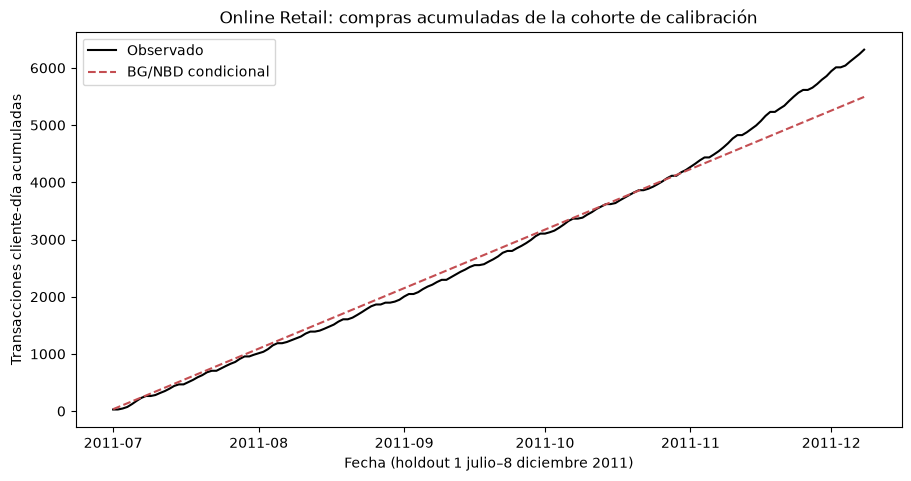

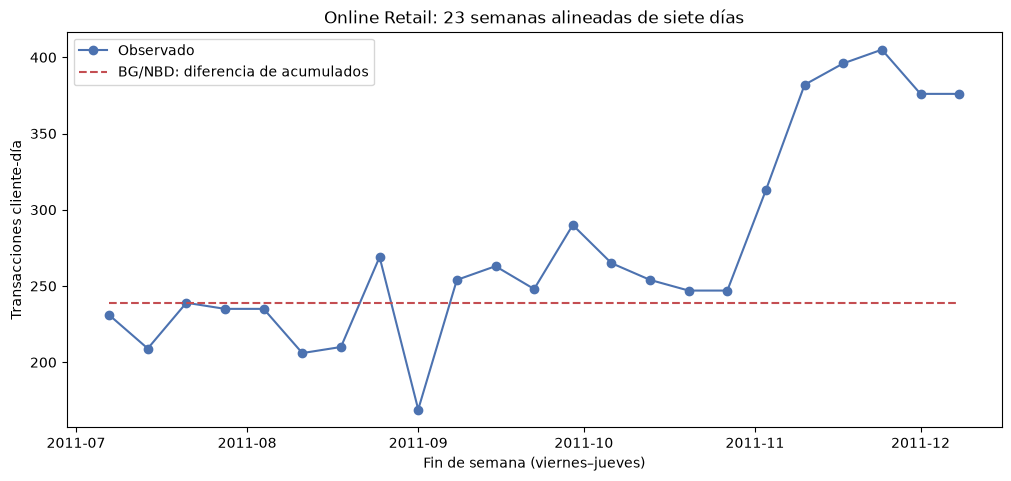

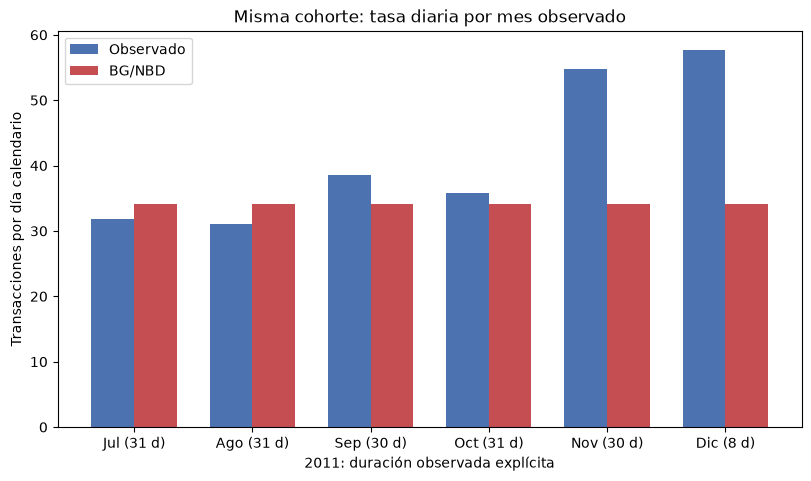

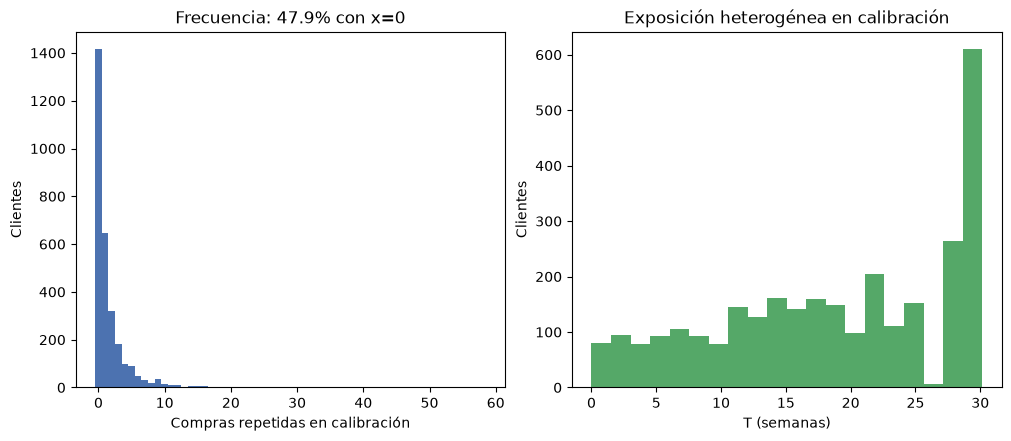

In [9]:
fig,ax=plt.subplots(figsize=(9,4.7),layout='constrained')
ax.plot(diario.fecha,diario.real_acumulado,label='Observado',color='black')
ax.plot(diario.fecha,diario.pronostico_acumulado,label='BG/NBD condicional',color='#C44E52',ls='--')
ax.set(title='Online Retail: compras acumuladas de la cohorte de calibración',
       xlabel='Fecha (holdout 1 julio–8 diciembre 2011)',ylabel='Transacciones cliente-día acumuladas')
ax.legend(); fig.savefig(FIGS/'parte5_holdout_acumulado.png',dpi=160); plt.show()

fig,ax=plt.subplots(figsize=(10,4.7),layout='constrained')
ax.plot(semanal.fecha_fin,semanal.real,marker='o',label='Observado',color='#4C72B0')
ax.plot(semanal.fecha_fin,semanal.pronostico,label='BG/NBD: diferencia de acumulados',color='#C44E52',ls='--')
ax.set(title='Online Retail: 23 semanas alineadas de siete días',xlabel='Fin de semana (viernes–jueves)',ylabel='Transacciones cliente-día')
ax.legend(); fig.savefig(FIGS/'parte5_holdout_semanal.png',dpi=160); plt.show()

fig,ax=plt.subplots(figsize=(8,4.7),layout='constrained')
pos=np.arange(len(mensual)); ancho=.36
ax.bar(pos-ancho/2,mensual.real_por_dia,ancho,label='Observado',color='#4C72B0')
ax.bar(pos+ancho/2,mensual.pronostico_por_dia,ancho,label='BG/NBD',color='#C44E52')
ax.set_xticks(pos,['Jul (31 d)','Ago (31 d)','Sep (30 d)','Oct (31 d)','Nov (30 d)','Dic (8 d)'])
ax.set(title='Misma cohorte: tasa diaria por mes observado',xlabel='2011: duración observada explícita',ylabel='Transacciones por día calendario')
ax.legend(); fig.savefig(FIGS/'parte5_meses_por_dia.png',dpi=160); plt.show()

fig,axes=plt.subplots(1,2,figsize=(10,4.3),layout='constrained')
axes[0].hist(x,bins=np.arange(0,int(x.max())+2)-.5,color='#4C72B0')
axes[0].set(title=f'Frecuencia: {(x==0).mean():.1%} con x=0',xlabel='Compras repetidas en calibración',ylabel='Clientes')
axes[1].hist(T,bins=20,color='#55A868')
axes[1].set(title='Exposición heterogénea en calibración',xlabel='T (semanas)',ylabel='Clientes')
fig.savefig(FIGS/'parte5_historias.png',dpi=160); plt.show()

In [10]:
archivos=['retail_dias.csv','retail_clientes.csv','retail_frecuencias.csv','retail_sensibilidad.csv',
          'retail_diario.csv','retail_semanal.csv','retail_mensual.csv',
          'retail_limpieza_auditoria.json','params_retail.json','retail_holdout.json']
proveniencia={'productor':'notebooks/05_online_retail.ipynb','datos':{
    'ruta':'data/Online Retail.xlsx','sha256':SHA_ORIGINAL,'fuente':origen['pagina_oficial']},
    'limpiador':{'funcion':'limpiar de la Tarea 3, luego netear_por_dia',
        'implementacion':'src/limpieza_retail.py','reglas':'reglas de limpiar; neto firmado cliente-día > 0 con devoluciones'},
    'origen_tiempo':INICIO_RETAIL.date().isoformat(),'fin_calibracion':FIN_CALIB_RETAIL.date().isoformat(),
    'inicio_holdout':'2011-07-01','fin_holdout':FIN_HOLDOUT_RETAIL.date().isoformat(),'tau_semanas':TAU,
    'cohorte':cohorte,'parametros':params,'ll_sumada':ll,'inicios_naturales':inicios_naturales,
    'diagnostico':diagnostico,'avisos':[str(v.message) for v in avisos],
    'interpretacion':interpretacion,'verificacion':verificacion,'versiones':versiones,
    'codigo_sha256':{f'src/{f}':sha(RAIZ/'src'/f) for f in
        ['limpieza_retail.py','pronostico_retail.py','datos.py','bgnbd.py']},
    'artefactos_sha256':{f'resultados/{f}':sha(RESULTADOS/f) for f in archivos},
    'params_cdnow_sha256_sin_modificar':cdnow_antes,
    'limitaciones':['cotas y débil identificación de a,b','una sola ventana para estacionalidad'],
    'cambio_compartido':False}
guardar('ajuste_retail_proveniencia.json',proveniencia)
assert sha(ruta)==SHA_ORIGINAL
assert sha(RESULTADOS/'params_cdnow.json')==cdnow_antes
print('Retail publicado; original y parámetros CDNOW intactos.')

Retail publicado; original y parámetros CDNOW intactos.


## Resumen

1. Una compra representa un cliente-día con venta neta positiva, después de devoluciones.
2. El pronóstico solo incluye clientes con compra calificante antes del corte; los nuevos
   del holdout no se mezclan. Se conservan quienes no regresan.
3. El ajuste se aproxima al límite sin abandono dentro de las cotas; convergencia
   no equivale a identificar con precisión las propensiones de abandono.
4. El total condicional subestima este holdout. Noviembre aumenta incluso ajustando
   por duración; diciembre parcial tiene una tasa diaria aún mayor.
5. Una intensidad estacionaria y una calibración corta limitan el pronóstico; el
   patrón observado no demuestra causalidad estacional ni una clasificación de mayoristas.

Reproducción y validación: `docs/parte5.md`.